In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
# open  cv return image shape as (H,W,"BGR channel")
IMAGE_PATH = "flower.jpg"   # photo notebook ke folder mein rakho
img = cv.imread(IMAGE_PATH)

if img is None:
    print(f"Could not read image: {IMAGE_PATH}")
else:
    print("type:", type(img))
    print("shape:", img.shape)
    print("dtype:", img.dtype)
    print("min, max:", img.min(), img.max())
    print("nbytes:", img.nbytes)

type: <class 'numpy.ndarray'>
shape: (670, 458, 3)
dtype: uint8
min, max: 0 255
nbytes: 920580


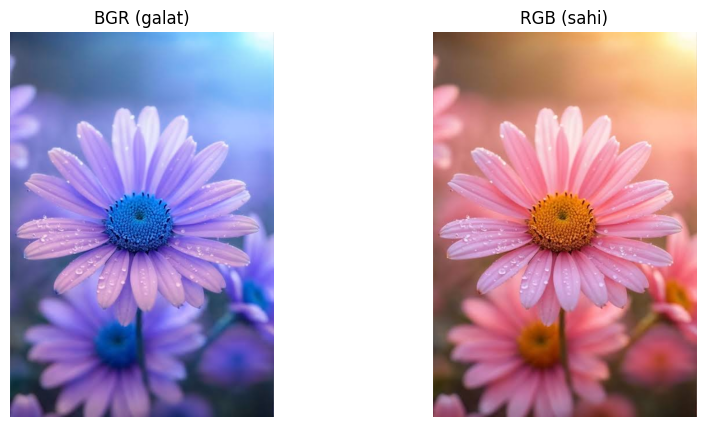

img shape: (670, 458, 3)
img_rgb shape: (670, 458, 3)
Same shape: True


In [14]:
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("BGR (galat)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_rgb)
plt.title("RGB (sahi)")
plt.axis("off")

plt.show()

print("img shape:", img.shape)
print("img_rgb shape:", img_rgb.shape)
print("Same shape:", img.shape == img_rgb.shape)

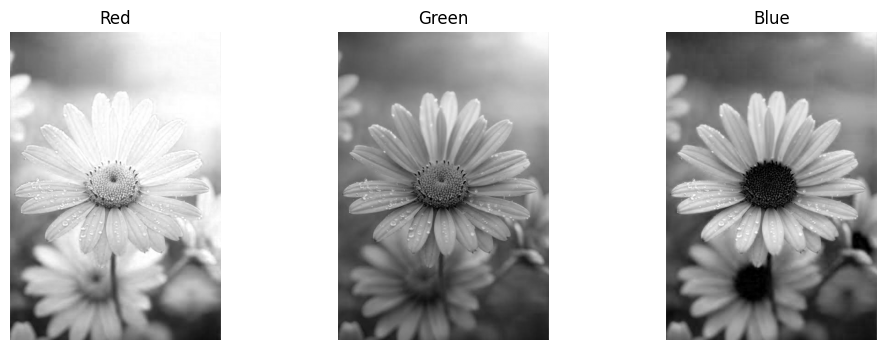

pixel [100, 200]: [177 121  86] (3,)
Red mean: 194.72006126572379
Green mean: 124.60306654500424
Blue mean: 123.74429707358405


In [16]:
red = img_rgb[:, :, 0]
green = img_rgb[:, :, 1]
blue = img_rgb[:, :, 2]

channels = [("Red", red), ("Green", green), ("Blue", blue)]

plt.figure(figsize=(12, 4))
for i, (name, channel) in enumerate(channels, start=1):
    plt.subplot(1, 3, i)
    plt.imshow(channel, cmap="gray")
    plt.title(name)
    plt.axis("off")
plt.show()

print("pixel [100, 200]:", img_rgb[100, 200], img_rgb[100, 200].shape)
for name, channel in channels:
    print(name, "mean:", channel.mean())

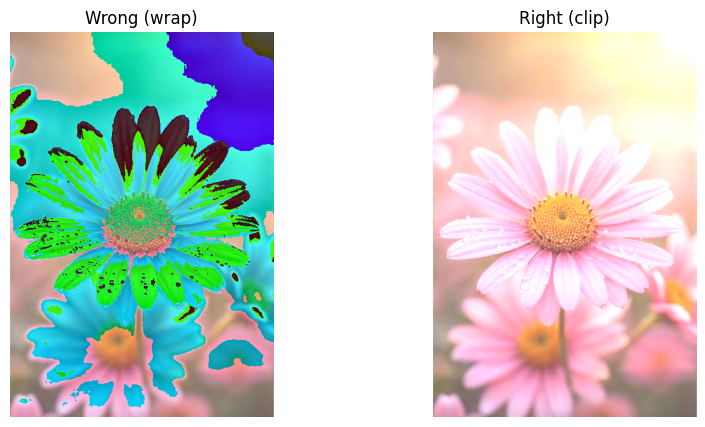

bright_wrong dtype: uint8
bright_right dtype: uint8
bright_right max: 255


In [17]:
bright_wrong = img_rgb + 80
bright_right = np.clip(img_rgb.astype(np.int16) + 80, 0, 255).astype(np.uint8)

images = [("Wrong (wrap)", bright_wrong), ("Right (clip)", bright_right)]

plt.figure(figsize=(10, 5))
for i, (title, image) in enumerate(images, start=1):
    plt.subplot(1, 2, i)
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
plt.show()

print("bright_wrong dtype:", bright_wrong.dtype)
print("bright_right dtype:", bright_right.dtype)
print("bright_right max:", bright_right.max())